In [3]:
from pathlib import Path
from collections import Counter

root = Path("/kaggle/input")
files = sorted(p for p in root.rglob("*") if p.is_file())

print("Total files:", len(files))

print("\nFile types:")
print(Counter(p.suffix.lower() for p in files))

print("\nFirst 30 file paths:")
for path in files[:30]:
    print(path.relative_to(root))

Total files: 2224

File types:
Counter({'.jpg': 1112, '.png': 1112})

First 30 file paths:
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0001.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0002.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0003.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0004.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0005.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0006.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0007.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0008.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0009.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0010.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0011.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0012.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/images/img_0013.jpg
datasets/nabilsherif/oil-spill/oil-spill/test/image

In [4]:
from pathlib import Path
from PIL import Image
import numpy as np

DATA_DIR = Path(
    "/kaggle/input/datasets/nabilsherif/oil-spill/oil-spill"
)

# نتأكد إن مسار الداتا صحيح
assert DATA_DIR.exists(), "Data folder not found"

# نعرض أسماء المجلدات وعدد الملفات داخل كل مجلد
for folder in sorted(DATA_DIR.rglob("*")):
    if folder.is_dir():
        count = sum(p.is_file() for p in folder.iterdir())
        print(folder.relative_to(DATA_DIR), ":", count, "files")

# نفحص ملفات التدريب فقط
train_images = sorted((DATA_DIR / "train").rglob("*.jpg"))
train_masks = sorted((DATA_DIR / "train").rglob("*.png"))

print("\nTraining images:", len(train_images))
print("Training masks:", len(train_masks))

print("\nFirst 3 image names:")
for path in train_images[:3]:
    print(path.relative_to(DATA_DIR))

print("\nFirst 3 mask names:")
for path in train_masks[:3]:
    print(path.relative_to(DATA_DIR))

# نفحص أول صورة وأول ماسك، قبل أي تغيير فيهم
if train_images and train_masks:
    with Image.open(train_images[0]) as img:
        print("\nImage size:", img.size)
        print("Image mode:", img.mode)

    with Image.open(train_masks[0]) as mask:
        print("\nMask size:", mask.size)
        print("Mask mode:", mask.mode)

        colors = np.unique(
            np.array(mask.convert("RGB")).reshape(-1, 3),
            axis=0
        )
        print("Colors in this mask:\n", colors)

test : 0 files
test/images : 110 files
test/labels : 110 files
train : 0 files
train/images : 1002 files
train/labels : 1002 files

Training images: 1002
Training masks: 1002

First 3 image names:
train/images/img_0001.jpg
train/images/img_0002.jpg
train/images/img_0003.jpg

First 3 mask names:
train/labels/img_0001.png
train/labels/img_0002.png
train/labels/img_0003.png

Image size: (1250, 650)
Image mode: RGB

Mask size: (1250, 650)
Mask mode: RGB
Colors in this mask:
 [[  0   0   0]
 [  0 255 255]]


Matched pairs: 1002
Missing masks: 0


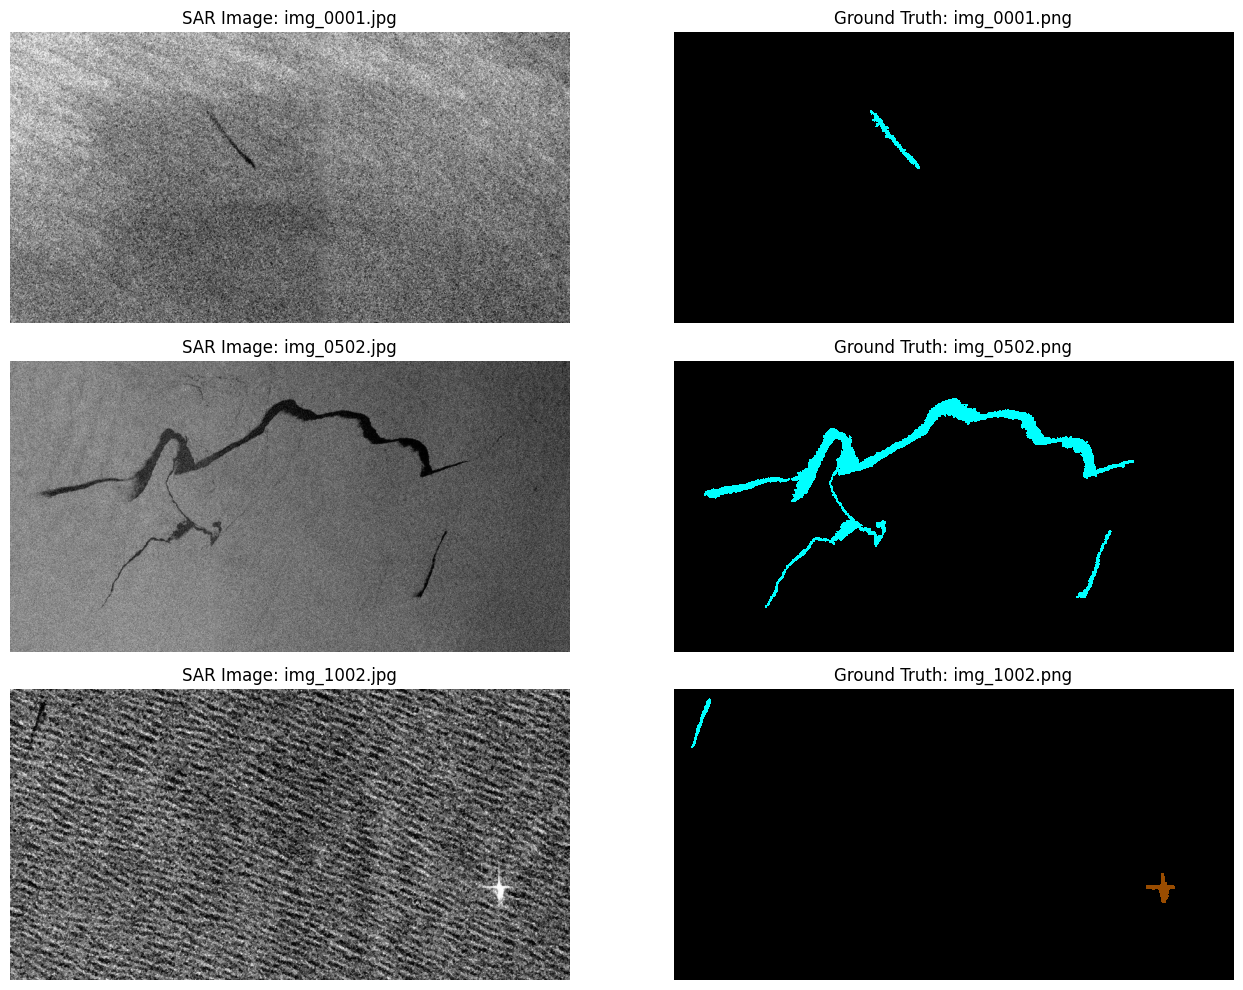

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_DIR = DATA_DIR / "train" / "images"
MASK_DIR = DATA_DIR / "train" / "labels"

image_paths = sorted(IMAGE_DIR.glob("*.jpg"))

pairs = []
missing_masks = []

for image_path in image_paths:
    mask_path = MASK_DIR / f"{image_path.stem}.png"

    if mask_path.exists():
        pairs.append((image_path, mask_path))
    else:
        missing_masks.append(image_path.name)

print("Matched pairs:", len(pairs))
print("Missing masks:", len(missing_masks))

assert not missing_masks, f"Missing masks: {missing_masks[:5]}"

selected_indices = [0, len(pairs) // 2, len(pairs) - 1]

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for row, index in enumerate(selected_indices):
    image_path, mask_path = pairs[index]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    with Image.open(mask_path) as mask_file:
        mask = mask_file.convert("RGB")

    assert image.size == mask.size, (
        f"Size mismatch: {image_path.name}"
    )

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"SAR Image: {image_path.name}")

    axes[row, 1].imshow(mask, interpolation="nearest")
    axes[row, 1].set_title(f"Ground Truth: {mask_path.name}")

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [6]:
from collections import Counter
from PIL import Image
from tqdm.auto import tqdm

CLASS_INFO = {
    (0, 0, 0):     (0, "Sea"),
    (0, 255, 255): (1, "Oil spill"),
    (255, 0, 0):   (2, "Look-alike"),
    (153, 76, 0):  (3, "Ships"),
    (0, 153, 0):   (4, "Land"),
}

color_counts = Counter()

for _, mask_path in tqdm(pairs, desc="Checking training masks"):
    with Image.open(mask_path) as mask:
        rgb_mask = mask.convert("RGB")

        colors = rgb_mask.getcolors(maxcolors=256)

        if colors is None:
            raise ValueError(
                f"More than 256 colors in {mask_path.name}. "
                "Inspect this mask before conversion."
            )

        for count, color in colors:
            color_counts[color] += count

total_pixels = sum(color_counts.values())

print("\nActual mask colors:")
for color, count in sorted(color_counts.items()):
    class_info = CLASS_INFO.get(color)
    name = class_info[1] if class_info else "UNKNOWN"
    percentage = 100 * count / total_pixels

    print(f"{str(color):18} {name:12} {percentage:.4f}%")

unknown_colors = set(color_counts) - set(CLASS_INFO)

assert not unknown_colors, (
    f"Unexpected colors found: {sorted(unknown_colors)}"
)

print("\nClass IDs:")
for color, (class_id, name) in CLASS_INFO.items():
    count = color_counts[color]
    print(f"{class_id}: {name} — {count:,} pixels")

print("\nColor check passed.")

Checking training masks:   0%|          | 0/1002 [00:00<?, ?it/s]


Actual mask colors:
(0, 0, 0)          Sea          88.0561%
(0, 153, 0)        Land         5.2653%
(0, 255, 255)      Oil spill    1.0062%
(153, 76, 0)       Ships        0.0426%
(255, 0, 0)        Look-alike   5.6297%

Class IDs:
0: Sea — 716,886,932 pixels
1: Oil spill — 8,192,020 pixels
2: Look-alike — 45,832,926 pixels
3: Ships — 346,855 pixels
4: Land — 42,866,267 pixels

Color check passed.


Before conversion: (650, 1250, 3)
After conversion: (650, 1250)
Data type: int64
Class IDs in this mask: [0 1]


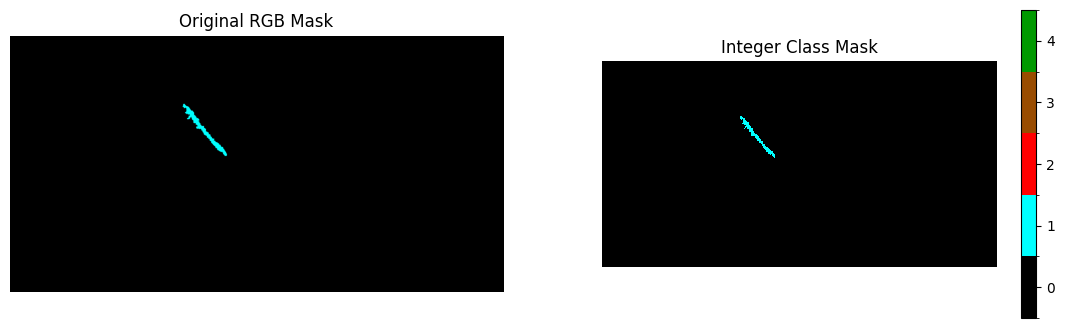

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from PIL import Image

def rgb_to_class_mask(rgb_mask):
    rgb = np.asarray(rgb_mask)

    if rgb.ndim != 3 or rgb.shape[2] != 3:
        raise ValueError(f"Expected RGB mask, got shape {rgb.shape}")

    # -1 مؤقتًا عشان نكتشف أي بكسل لونه مش معروف
    labels = np.full(rgb.shape[:2], -1, dtype=np.int64)

    for color, (class_id, _) in CLASS_INFO.items():
        matches = np.all(rgb == color, axis=-1)
        labels[matches] = class_id

    if np.any(labels == -1):
        unknown = np.unique(rgb[labels == -1], axis=0)
        raise ValueError(f"Unknown mask colors: {unknown.tolist()}")

    return labels


# نجرب التحويل على أول ماسك
with Image.open(pairs[0][1]) as mask_file:
    rgb_mask = np.array(mask_file.convert("RGB"))

label_mask = rgb_to_class_mask(rgb_mask)

print("Before conversion:", rgb_mask.shape)
print("After conversion:", label_mask.shape)
print("Data type:", label_mask.dtype)
print("Class IDs in this mask:", np.unique(label_mask))

# نعيد استخدام ألوان الفئات للعرض فقط
class_colors = np.array([
    [0, 0, 0],
    [0, 255, 255],
    [255, 0, 0],
    [153, 76, 0],
    [0, 153, 0],
]) / 255.0

cmap = ListedColormap(class_colors)
norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), cmap.N)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].imshow(rgb_mask)
axes[0].set_title("Original RGB Mask")
axes[0].axis("off")

display = axes[1].imshow(
    label_mask,
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)
axes[1].set_title("Integer Class Mask")
axes[1].axis("off")

fig.colorbar(display, ax=axes[1], ticks=range(5))
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import json

SEED = 42


all_pairs = sorted(pairs, key=lambda pair: pair[0].name)

train_pairs, val_pairs = train_test_split(
    all_pairs,
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)


train_names = {image.name for image, mask in train_pairs}
val_names = {image.name for image, mask in val_pairs}

assert train_names.isdisjoint(val_names)
assert len(train_pairs) + len(val_pairs) == len(all_pairs)

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Shared images:", len(train_names & val_names))


split_info = {
    "seed": SEED,
    "source": "official_train",
    "train": sorted(train_names),
    "validation": sorted(val_names)
}

split_path = Path("/kaggle/working/split_seed42.json")

with split_path.open("w", encoding="utf-8") as file:
    json.dump(split_info, file, indent=2)

print("\nSplit saved to:", split_path)

Training pairs: 801
Validation pairs: 201
Shared images: 0

Split saved to: /kaggle/working/split_seed42.json


In [9]:
import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

SEED = 42
IMAGE_SIZE = (256, 256)  # width, height
BATCH_SIZE = 8

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


class OilSpillDataset(Dataset):
    def __init__(self, pairs, augment=False):
        self.pairs = pairs
        self.augment = augment

        # ImageNet normalization for the selected pretrained encoder
        self.mean = torch.tensor(
            [0.485, 0.456, 0.406], dtype=torch.float32
        ).view(3, 1, 1)

        self.std = torch.tensor(
            [0.229, 0.224, 0.225], dtype=torch.float32
        ).view(3, 1, 1)

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]

        with Image.open(image_path) as file:
            image = file.convert("RGB")

        with Image.open(mask_path) as file:
            mask = file.convert("RGB")

        # Image: smooth resizing
        image = image.resize(
            IMAGE_SIZE, resample=Image.Resampling.BILINEAR
        )

        # Mask: preserve exact class colors
        mask = mask.resize(
            IMAGE_SIZE, resample=Image.Resampling.NEAREST
        )

        # Apply the SAME random flips to image and mask
        if self.augment:
            if torch.rand(()).item() < 0.5:
                image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
                mask = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT)

            if torch.rand(()).item() < 0.5:
                image = image.transpose(Image.Transpose.FLIP_TOP_BOTTOM)
                mask = mask.transpose(Image.Transpose.FLIP_TOP_BOTTOM)

        # Image: HWC -> CHW, and values 0–255 -> 0–1
        image = np.array(image, dtype=np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1).contiguous()

        image = (image - self.mean) / self.std

        # Mask: RGB -> integer class IDs
        mask = rgb_to_class_mask(np.array(mask))
        mask = torch.from_numpy(mask).long()

        return image, mask


train_dataset = OilSpillDataset(train_pairs, augment=True)
val_dataset = OilSpillDataset(val_pairs, augment=False)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    # Avoid a final batch of only one image during training
    drop_last=True,
    generator=loader_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Check one batch
images, masks = next(iter(train_loader))

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)
print("Images dtype:", images.dtype)
print("Masks dtype:", masks.dtype)
print("Class IDs in this batch:", torch.unique(masks))

assert images.shape == (BATCH_SIZE, 3, 256, 256)
assert masks.shape == (BATCH_SIZE, 256, 256)
assert masks.min() >= 0 and masks.max() <= 4

print("\nBatch check passed.")

Images shape: torch.Size([8, 3, 256, 256])
Masks shape: torch.Size([8, 256, 256])
Images dtype: torch.float32
Masks dtype: torch.int64
Class IDs in this batch: tensor([0, 1, 2, 3, 4])

Batch check passed.


In [14]:
%pip install -q segmentation-models-pytorch==0.5.0

Note: you may need to restart the kernel to use updated packages.


In [15]:
import torch
import segmentation_models_pytorch as smp

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch version:", torch.__version__)
print("SMP version:", smp.__version__)

# تحميل الـBackbone بأوزان ImageNet
model = smp.DeepLabV3Plus(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=5,
    activation=None
)

# تثبيت أوزان الـBackbone
for parameter in model.encoder.parameters():
    parameter.requires_grad = False

model = model.to(device)

# وضع التدريب، مع إبقاء الـEncoder ثابتًا
model.train()
model.encoder.eval()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

assert all(
    not p.requires_grad for p in model.encoder.parameters()
)
assert trainable_params > 0

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

# تجربة مرور صورتين داخل الموديل بدون تدريب
model.eval()

with torch.no_grad():
    sample_images = images[:2].to(device)
    logits = model(sample_images)
    predicted_masks = logits.argmax(dim=1)

print("\nInput shape:", sample_images.shape)
print("Output shape:", logits.shape)
print("Predicted masks shape:", predicted_masks.shape)

assert logits.shape == (2, 5, 256, 256)
assert predicted_masks.shape == (2, 256, 256)

print("\nModel check passed.")

Device: cuda
PyTorch version: 2.11.0+cu128
SMP version: 0.5.0


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            


Total parameters: 22,438,485
Trainable parameters: 1,153,813
Frozen parameters: 21,284,672

Input shape: torch.Size([2, 3, 256, 256])
Output shape: torch.Size([2, 5, 256, 256])
Predicted masks shape: torch.Size([2, 256, 256])

Model check passed.


In [16]:
import torch.nn as nn

ce_loss = nn.CrossEntropyLoss()

dice_loss = smp.losses.DiceLoss(
    mode="multiclass",
    from_logits=True
)

def criterion(logits, targets):
    return ce_loss(logits, targets) + dice_loss(logits, targets)


optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-3,
    weight_decay=1e-4
)

# نجرب حساب الـLoss بدون تحديث الأوزان
check_images, check_masks = next(iter(val_loader))

check_images = check_images[:2].to(device)
check_masks = check_masks[:2].to(device)

model.eval()

with torch.no_grad():
    check_logits = model(check_images)

    ce_value = ce_loss(check_logits, check_masks)
    dice_value = dice_loss(check_logits, check_masks)
    total_loss = criterion(check_logits, check_masks)

assert torch.isfinite(total_loss), "Loss is NaN or infinity"

print(f"Cross-Entropy: {ce_value.item():.4f}")
print(f"Dice Loss:     {dice_value.item():.4f}")
print(f"Total Loss:    {total_loss.item():.4f}")
print("\nLoss check passed.")

Cross-Entropy: 1.5848
Dice Loss:     0.5244
Total Loss:    2.1092

Loss check passed.


In [17]:
CLASS_NAMES = ["Sea", "Oil spill", "Look-alike", "Ships", "Land"]
NUM_CLASSES = len(CLASS_NAMES)


@torch.no_grad()
def batch_confusion_matrix(targets, predictions):
    # Rows: true classes, columns: predicted classes
    targets = targets.detach().to("cpu", dtype=torch.int64)
    predictions = predictions.detach().to("cpu", dtype=torch.int64)

    if targets.shape != predictions.shape:
        raise ValueError("Targets and predictions must have the same shape")

    targets = targets.reshape(-1)
    predictions = predictions.reshape(-1)

    valid = (
        (targets >= 0) & (targets < NUM_CLASSES)
        & (predictions >= 0) & (predictions < NUM_CLASSES)
    )

    if not valid.all().item():
        raise ValueError("Class IDs must be between 0 and 4")

    indices = NUM_CLASSES * targets + predictions

    return torch.bincount(
        indices,
        minlength=NUM_CLASSES ** 2
    ).reshape(NUM_CLASSES, NUM_CLASSES)


def metrics_from_confusion(confusion):
    cm = confusion.to(dtype=torch.float64, device="cpu")

    if cm.sum().item() == 0:
        raise ValueError("Cannot evaluate an empty confusion matrix")

    correct = cm.diag()
    true_pixels = cm.sum(dim=1)
    predicted_pixels = cm.sum(dim=0)

    union = true_pixels + predicted_pixels - correct
    dice_denominator = true_pixels + predicted_pixels

    # Undefined if a class is absent from BOTH truth and predictions
    nan_values = torch.full_like(correct, float("nan"))

    iou = torch.where(
        union > 0,
        correct / union,
        nan_values
    )

    dice = torch.where(
        dice_denominator > 0,
        2 * correct / dice_denominator,
        nan_values
    )

    return {
        "miou": torch.nanmean(iou).item(),
        "mean_dice": torch.nanmean(dice).item(),
        "pixel_accuracy": (correct.sum() / cm.sum()).item(),
        "per_class_iou": iou.tolist(),
        "per_class_dice": dice.tolist()
    }


# Small checks with known answers — NOT model results
toy_true = torch.tensor([[0, 1, 2, 3, 4]])

perfect_cm = batch_confusion_matrix(toy_true, toy_true)
perfect_scores = metrics_from_confusion(perfect_cm)

assert perfect_scores["miou"] == 1.0
assert perfect_scores["mean_dice"] == 1.0
assert perfect_scores["pixel_accuracy"] == 1.0

wrong_prediction = torch.tensor([[1, 2, 3, 4, 0]])
wrong_cm = batch_confusion_matrix(toy_true, wrong_prediction)
wrong_scores = metrics_from_confusion(wrong_cm)

assert wrong_scores["miou"] == 0.0
assert wrong_scores["mean_dice"] == 0.0
assert wrong_scores["pixel_accuracy"] == 0.0

print("Metrics checks passed.")

Metrics checks passed.


In [18]:
import time
import json
from pathlib import Path
from tqdm.auto import tqdm


def run_epoch(loader, training):
    if training:
        model.train()
        model.encoder.eval()  # Keep frozen backbone statistics fixed
    else:
        model.eval()

    confusion = torch.zeros(
        NUM_CLASSES, NUM_CLASSES, dtype=torch.int64
    )
    loss_sum = 0.0
    sample_count = 0

    progress = tqdm(
        loader,
        desc="Training" if training else "Validation",
        leave=False
    )

    for batch_images, batch_masks in progress:
        batch_images = batch_images.to(device, non_blocking=True)
        batch_masks = batch_masks.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(batch_images)
            loss = criterion(outputs, batch_masks)

            if not torch.isfinite(loss).item():
                raise ValueError("Non-finite loss detected")

            if training:
                loss.backward()
                optimizer.step()

        batch_size = batch_images.size(0)

        # Sample-weighted average of batch CE + Dice losses
        loss_sum += loss.item() * batch_size
        sample_count += batch_size

        predictions = outputs.detach().argmax(dim=1)
        confusion += batch_confusion_matrix(
            batch_masks, predictions
        )

        progress.set_postfix(
            loss=f"{loss_sum / sample_count:.4f}"
        )

    scores = metrics_from_confusion(confusion)
    scores["loss"] = loss_sum / sample_count
    scores["confusion_matrix"] = confusion

    return scores

In [19]:
OUTPUT_DIR = Path("/kaggle/working/deeplab_frozen_exp1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Protect a previous run from accidental overwriting
if (OUTPUT_DIR / "last_checkpoint.pth").exists():
    raise RuntimeError(
        "A saved run already exists. Resume it instead of starting again."
    )

assert device.type == "cuda", "Enable GPU before starting training."

EPOCHS = 2

config = {
    "experiment": "deeplab_frozen_exp1",
    "architecture": "DeepLabV3Plus",
    "encoder": "resnet34",
    "encoder_weights": "imagenet",
    "encoder_frozen": True,
    "encoder_batchnorm": "eval",
    "image_size": list(IMAGE_SIZE),
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "augmentation": "horizontal and vertical flips, p=0.5 each",
    "loss": "CrossEntropy + multiclass Dice, equal coefficients",
    "optimizer": "AdamW",
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": BATCH_SIZE,
    "train_drop_last": True,
    "seed": SEED,
    "checkpoint_selection": "highest validation mIoU",
    "absent_class_policy": "exclude if absent from truth and predictions",
    "evaluation_resolution": list(IMAGE_SIZE),
    "class_names": CLASS_NAMES,
    "torch_version": str(torch.__version__),
    "smp_version": smp.__version__
}

with (OUTPUT_DIR / "config.json").open("w") as file:
    json.dump(config, file, indent=2)

# Save the exact split alongside this experiment
with (OUTPUT_DIR / "split.json").open("w") as file:
    json.dump(split_info, file, indent=2)

history = []
best_miou = -1.0
best_epoch = None


def save_checkpoint(checkpoint, destination):
    temporary = destination.with_suffix(".tmp")
    torch.save(checkpoint, temporary)
    temporary.replace(destination)


for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_scores = run_epoch(train_loader, training=True)
    val_scores = run_epoch(val_loader, training=False)

    elapsed = time.perf_counter() - start

    row = {
        "epoch": epoch,
        "train_loss": train_scores["loss"],
        "val_loss": val_scores["loss"],
        "train_miou": train_scores["miou"],
        "val_miou": val_scores["miou"],
        "train_mean_dice": train_scores["mean_dice"],
        "val_mean_dice": val_scores["mean_dice"],
        "train_accuracy": train_scores["pixel_accuracy"],
        "val_accuracy": val_scores["pixel_accuracy"],
        "seconds": elapsed
    }
    history.append(row)

    improved = val_scores["miou"] > best_miou

    if improved:
        best_miou = val_scores["miou"]
        best_epoch = epoch

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_miou": best_miou,
        "best_epoch": best_epoch,
        "history": history,
        "config": config,
        "train_scores": train_scores,
        "val_scores": val_scores,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all(),
        "loader_rng_state": loader_generator.get_state(),
        "numpy_rng_state": np.random.get_state(),
        "python_rng_state": random.getstate()
    }

    save_checkpoint(
        checkpoint, OUTPUT_DIR / "last_checkpoint.pth"
    )

    if improved:
        save_checkpoint(
            checkpoint, OUTPUT_DIR / "best_checkpoint.pth"
        )

    history_path = OUTPUT_DIR / "history.json"
    temporary_history = OUTPUT_DIR / "history.tmp"

    with temporary_history.open("w") as file:
        json.dump(history, file, indent=2, allow_nan=False)

    temporary_history.replace(history_path)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Train loss: {row['train_loss']:.4f} | "
        f"Val loss: {row['val_loss']:.4f} | "
        f"Train mIoU: {row['train_miou']:.4f} | "
        f"Val mIoU: {row['val_miou']:.4f} | "
        f"Time: {elapsed / 60:.2f} min",
        flush=True
    )

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation mIoU: {best_miou:.4f}")
print("Saved to:", OUTPUT_DIR)

Training:   0%|          | 0/100 [00:00<?, ?it/s]

Validation:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch 1/2 | Train loss: 0.8321 | Val loss: 0.5895 | Train mIoU: 0.4230 | Val mIoU: 0.5362 | Time: 2.11 min


Training:   0%|          | 0/100 [00:00<?, ?it/s]

Validation:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch 2/2 | Train loss: 0.6113 | Val loss: 0.5804 | Train mIoU: 0.5181 | Val mIoU: 0.5388 | Time: 0.76 min

Best epoch: 2
Best validation mIoU: 0.5388
Saved to: /kaggle/working/deeplab_frozen_exp1


In [20]:
# Resume OUR saved checkpoint, including optimizer and random states
checkpoint = torch.load(
    OUTPUT_DIR / "last_checkpoint.pth",
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

history = checkpoint["history"]
best_miou = checkpoint["best_miou"]
best_epoch = checkpoint["best_epoch"]
config = checkpoint["config"]

torch.set_rng_state(checkpoint["torch_rng_state"])
torch.cuda.set_rng_state_all(checkpoint["cuda_rng_states"])
loader_generator.set_state(checkpoint["loader_rng_state"])
np.random.set_state(checkpoint["numpy_rng_state"])
random.setstate(checkpoint["python_rng_state"])

TOTAL_EPOCHS = 30
start_epoch = checkpoint["epoch"] + 1

config["planned_total_epochs"] = TOTAL_EPOCHS

with (OUTPUT_DIR / "config.json").open("w") as file:
    json.dump(config, file, indent=2)

print(f"Resuming from epoch {start_epoch}")
print(f"Current best validation mIoU: {best_miou:.4f}")

for epoch in range(start_epoch, TOTAL_EPOCHS + 1):
    start = time.perf_counter()

    train_scores = run_epoch(train_loader, training=True)
    val_scores = run_epoch(val_loader, training=False)

    elapsed = time.perf_counter() - start

    row = {
        "epoch": epoch,
        "train_loss": train_scores["loss"],
        "val_loss": val_scores["loss"],
        "train_miou": train_scores["miou"],
        "val_miou": val_scores["miou"],
        "train_mean_dice": train_scores["mean_dice"],
        "val_mean_dice": val_scores["mean_dice"],
        "train_accuracy": train_scores["pixel_accuracy"],
        "val_accuracy": val_scores["pixel_accuracy"],
        "seconds": elapsed
    }
    history.append(row)

    improved = val_scores["miou"] > best_miou

    if improved:
        best_miou = val_scores["miou"]
        best_epoch = epoch

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_miou": best_miou,
        "best_epoch": best_epoch,
        "history": history,
        "config": config,
        "train_scores": train_scores,
        "val_scores": val_scores,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all(),
        "loader_rng_state": loader_generator.get_state(),
        "numpy_rng_state": np.random.get_state(),
        "python_rng_state": random.getstate()
    }

    save_checkpoint(
        checkpoint, OUTPUT_DIR / "last_checkpoint.pth"
    )

    if improved:
        save_checkpoint(
            checkpoint, OUTPUT_DIR / "best_checkpoint.pth"
        )

    temporary_history = OUTPUT_DIR / "history.tmp"

    with temporary_history.open("w") as file:
        json.dump(history, file, indent=2, allow_nan=False)

    temporary_history.replace(OUTPUT_DIR / "history.json")

    print(
        f"Epoch {epoch}/{TOTAL_EPOCHS} | "
        f"Train loss: {row['train_loss']:.4f} | "
        f"Val loss: {row['val_loss']:.4f} | "
        f"Train mIoU: {row['train_miou']:.4f} | "
        f"Val mIoU: {row['val_miou']:.4f} | "
        f"Time: {elapsed / 60:.2f} min"
        + (" | BEST" if improved else ""),
        flush=True
    )

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation mIoU: {best_miou:.4f}")
print("Training completed.")

Resuming from epoch 3
Current best validation mIoU: 0.5388


Training:   0%|          | 0/100 [00:00<?, ?it/s]

Validation:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch 3/30 | Train loss: 0.5505 | Val loss: 0.5467 | Train mIoU: 0.5809 | Val mIoU: 0.5724 | Time: 0.75 min | BEST


Training:   0%|          | 0/100 [00:00<?, ?it/s]

Validation:   0%|          | 0/26 [00:00<?, ?it/s]

... (75 outputs left out)

Epoch 29/30 | Train loss: 0.3083 | Val loss: 0.4526 | Train mIoU: 0.7316 | Val mIoU: 0.6445 | Time: 0.76 min


Training:   0%|          | 0/100 [00:00<?, ?it/s]

Validation:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch 30/30 | Train loss: 0.3282 | Val loss: 0.4557 | Train mIoU: 0.7220 | Val mIoU: 0.6394 | Time: 0.76 min

Best epoch: 16
Best validation mIoU: 0.6588
Training completed.


Selected epoch: 16
Validation mIoU: 0.6588
Validation mean Dice: 0.7712
Validation pixel accuracy: 0.9593
Total logged epoch time: 24.12 minutes


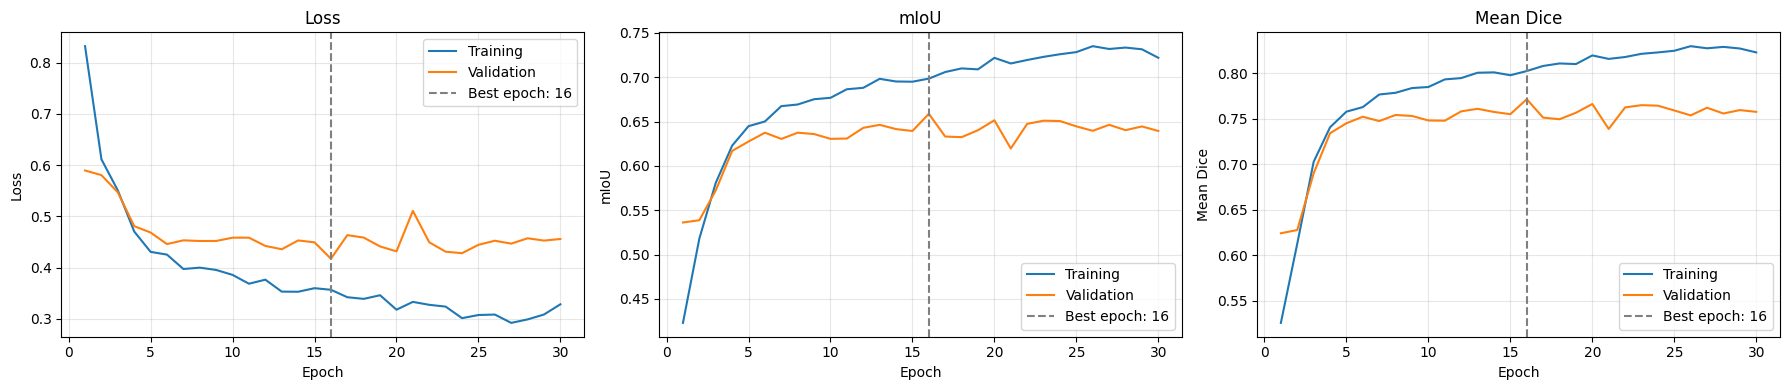


Best-checkpoint validation results:


TypeError: 'AxesImage' object is not callable

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Use ALL 30 epochs for the curves
with (OUTPUT_DIR / "history.json").open() as file:
    full_history = json.load(file)

history_df = pd.DataFrame(full_history)

# Load the checkpoint selected using validation mIoU
best_checkpoint = torch.load(
    OUTPUT_DIR / "best_checkpoint.pth",
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

selected_epoch = best_checkpoint["epoch"]
best_scores = best_checkpoint["val_scores"]

print("Selected epoch:", selected_epoch)
print(f"Validation mIoU: {best_scores['miou']:.4f}")
print(f"Validation mean Dice: {best_scores['mean_dice']:.4f}")
print(f"Validation pixel accuracy: {best_scores['pixel_accuracy']:.4f}")
print(
    "Total logged epoch time:",
    f"{history_df['seconds'].sum() / 60:.2f} minutes"
)

# Training history
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

plot_settings = [
    ("loss", "Loss"),
    ("miou", "mIoU"),
    ("mean_dice", "Mean Dice")
]

for ax, (key, title) in zip(axes, plot_settings):
    ax.plot(
        history_df["epoch"], history_df[f"train_{key}"],
        label="Training"
    )
    ax.plot(
        history_df["epoch"], history_df[f"val_{key}"],
        label="Validation"
    )
    ax.axvline(
        selected_epoch, color="gray",
        linestyle="--", label=f"Best epoch: {selected_epoch}"
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "training_curves.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# Per-class VALIDATION results from the selected checkpoint
class_results = pd.DataFrame({
    "Class": CLASS_NAMES,
    "IoU": best_scores["per_class_iou"],
    "Dice": best_scores["per_class_dice"]
})

print("\nBest-checkpoint validation results:")
display(class_results.round(4))

history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
class_results.to_csv(
    OUTPUT_DIR / "validation_per_class.csv", index=False
)

print("\nCurves and tables saved.")

In [22]:
from IPython.display import display as show_table

show_table(class_results.round(4))

history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)

class_results.to_csv(
    OUTPUT_DIR / "validation_per_class.csv",
    index=False
)

print("Tables saved successfully.")

,Class,IoU,Dice
0,Sea,0.9566,0.9778
1,Oil spill,0.5167,0.6814
2,Look-alike,0.5663,0.7231
3,Ships,0.3608,0.5302
4,Land,0.8934,0.9437


Tables saved successfully.


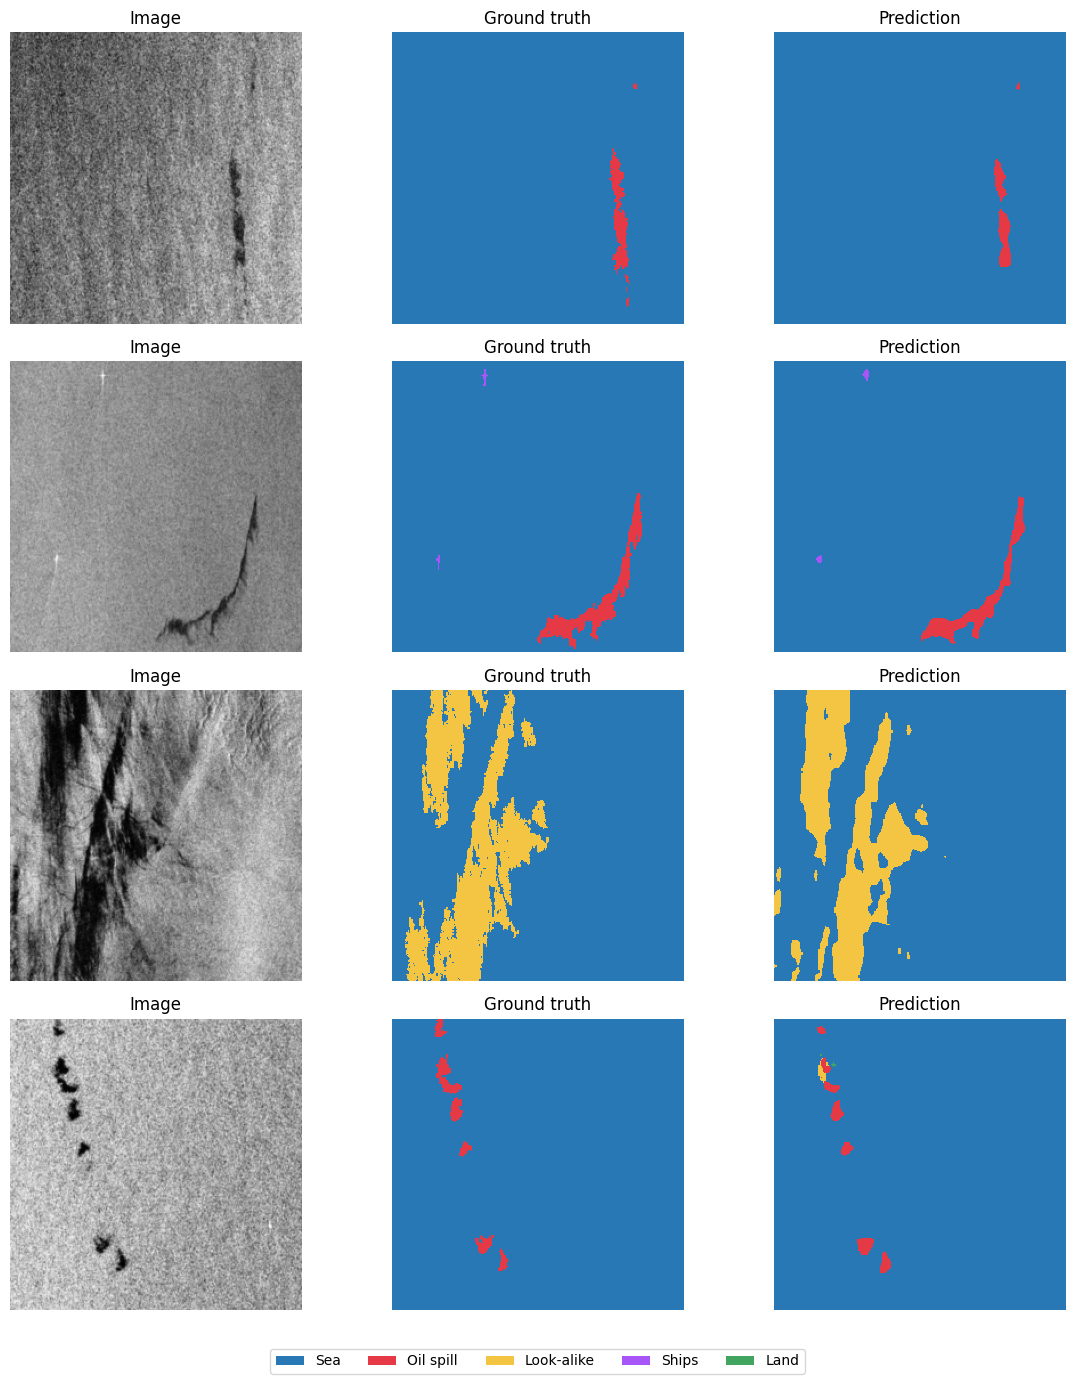

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Fixed colors for class IDs 0–4
colors = ["#2878B5", "#E63946", "#F4C542", "#A855F7", "#42A55F"]
class_cmap = ListedColormap(colors)
class_norm = BoundaryNorm(np.arange(NUM_CLASSES + 1) - 0.5, NUM_CLASSES)

images, masks = next(iter(val_loader))
n = min(4, images.size(0))

model.eval()
with torch.no_grad():
    predictions = model(images[:n].to(device)).argmax(dim=1).cpu()

# Undo ImageNet normalization for display only
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
visible_images = (
    images[:n].detach().cpu() * std + mean
).clamp(0, 1)

fig, axes = plt.subplots(
    n, 3, figsize=(12, 3.5 * n), squeeze=False
)

for i in range(n):
    axes[i, 0].imshow(visible_images[i].permute(1, 2, 0))
    axes[i, 1].imshow(
        masks[i].cpu(), cmap=class_cmap, norm=class_norm,
        interpolation="nearest"
    )
    axes[i, 2].imshow(
        predictions[i], cmap=class_cmap, norm=class_norm,
        interpolation="nearest"
    )

    for j, title in enumerate(["Image", "Ground truth", "Prediction"]):
        axes[i, j].set_title(title)
        axes[i, j].axis("off")

legend = [
    Patch(facecolor=color, label=name)
    for color, name in zip(colors, CLASS_NAMES)
]
fig.legend(
    handles=legend, loc="lower center",
    ncol=NUM_CLASSES, bbox_to_anchor=(0.5, 0.01)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(
    OUTPUT_DIR / "validation_predictions.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

In [27]:

# Official test images and masks
TEST_IMAGE_DIR = DATA_DIR / "test" / "images"
TEST_MASK_DIR = DATA_DIR / "test" / "labels"

assert TEST_IMAGE_DIR.is_dir(), f"Folder not found: {TEST_IMAGE_DIR}"
assert TEST_MASK_DIR.is_dir(), f"Folder not found: {TEST_MASK_DIR}"

test_image_paths = sorted(
    path for path in TEST_IMAGE_DIR.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg"}
)

test_pairs = []
missing_masks = []

for image_path in test_image_paths:
    mask_path = TEST_MASK_DIR / f"{image_path.stem}.png"

    if mask_path.is_file():
        test_pairs.append((image_path, mask_path))
    else:
        missing_masks.append(image_path.name)

assert test_pairs, "No test image/mask pairs found"
assert not missing_masks, f"Missing test masks: {missing_masks[:5]}"

# Same preprocessing as Validation, without augmentation
test_dataset = OilSpillDataset(test_pairs, augment=False)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("Test loader ready.")

Test images: 110
Test batches: 14
Test loader ready.


In [32]:
from PIL import Image
from tqdm import tqdm
from IPython.display import display as show_table
import pandas as pd
import json

IGNORE_ID = 255


class TestDatasetWithIgnore(OilSpillDataset):
    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]

        with Image.open(image_path) as file:
            image = file.convert("RGB")

        with Image.open(mask_path) as file:
            rgb = np.array(file.convert("RGB"))

        # Map known colors; leave unknown pixels as IGNORE_ID.
        labels = np.full(rgb.shape[:2], IGNORE_ID, dtype=np.uint8)

        for color, (class_id, _) in CLASS_INFO.items():
            labels[np.all(rgb == color, axis=-1)] = class_id

        # Nearest-neighbor resizing preserves class IDs and IGNORE_ID.
        mask = Image.fromarray(labels).resize(
            IMAGE_SIZE, resample=Image.Resampling.NEAREST
        )

        image = image.resize(
            IMAGE_SIZE, resample=Image.Resampling.BILINEAR
        )
        image = np.array(image, dtype=np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1).contiguous()
        image = (image - self.mean) / self.std

        mask = torch.from_numpy(np.array(mask, dtype=np.int64))

        return image, mask


test_dataset = TestDatasetWithIgnore(test_pairs, augment=False)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

# Use the best checkpoint already loaded from your completed training.
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

confusion = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64)
ignored_pixels = 0
evaluated_pixels = 0

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Test"):
        predictions = model(images.to(device)).argmax(dim=1).cpu()

        valid = masks != IGNORE_ID
        ignored_pixels += (~valid).sum().item()
        evaluated_pixels += valid.sum().item()

        confusion += batch_confusion_matrix(
            masks[valid], predictions[valid]
        )

test_scores = metrics_from_confusion(confusion)

print("Selected epoch:", best_checkpoint["epoch"])
print(f"Test mIoU:           {test_scores['miou']:.4f}")
print(f"Test mean Dice:      {test_scores['mean_dice']:.4f}")
print(f"Test pixel accuracy: {test_scores['pixel_accuracy']:.4f}")
print("Ignored pixels at evaluation resolution:", ignored_pixels)

test_results = pd.DataFrame({
    "Class": CLASS_NAMES,
    "IoU": test_scores["per_class_iou"],
    "Dice": test_scores["per_class_dice"]
})

show_table(test_results.round(4))

test_results.to_csv(OUTPUT_DIR / "test_per_class.csv", index=False)

pd.DataFrame(
    confusion.numpy(), index=CLASS_NAMES, columns=CLASS_NAMES
).to_csv(OUTPUT_DIR / "test_confusion_matrix.csv")

# Convert undefined class metrics to JSON null.
saved_scores = {
    key: [
        value if np.isfinite(value) else None
        for value in values
    ] if isinstance(values, list) else values
    for key, values in test_scores.items()
}

with (OUTPUT_DIR / "test_metrics.json").open("w") as file:
    json.dump({
        "selected_epoch": best_checkpoint["epoch"],
        "evaluation_resolution": list(IMAGE_SIZE),
        "unknown_color_policy": "exclude from evaluation",
        "ignored_pixels": ignored_pixels,
        "evaluated_pixels": evaluated_pixels,
        "metrics": saved_scores
    }, file, indent=2, allow_nan=False)

print("Test results saved.")

Test: 100%|██████████| 14/14 [00:22<00:00,  1.58s/it]

Selected epoch: 16
Test mIoU:           0.6509
Test mean Dice:      0.7616
Test pixel accuracy: 0.9649
Ignored pixels at evaluation resolution: 22


,Class,IoU,Dice
0,Sea,0.9637,0.9815
1,Oil spill,0.4895,0.6573
2,Look-alike,0.5753,0.7304
3,Ships,0.3255,0.4911
4,Land,0.9004,0.9476


Test results saved.


In [33]:
import shutil
from IPython.display import FileLink, display as show_output

assert (OUTPUT_DIR / "best_checkpoint.pth").is_file()
assert (OUTPUT_DIR / "last_checkpoint.pth").is_file()

archive_path = shutil.make_archive(
    str(OUTPUT_DIR) + "_FINAL",
    "zip",
    root_dir=OUTPUT_DIR
)

show_output(FileLink(archive_path))

/kaggle/working/deeplab_frozen_exp1_FINAL.zip